# Gym Member Analytics: Churn Prediction & Marketing Inferences using BSTS

This notebook implements an end-to-end data science and business analytics pipeline tailored for high-volume, membership-based business models (e.g., Planet Fitness, WHOOP, Basic-Fit). 

### Strategic Objectives:
1. **Behavioral Churn Prediction:** Enrich transactional gym check-in records with wearable biomarkers (HRV, chronic stress tracking) to predict cancellation propensity before it happens.
2. **Causal Marketing Attribution:** Apply Google's **Bayesian Structural Time Series (BSTS)** framework to isolate and quantify the true incremental lift of an aggressive promotional campaign, separating marketing ROI from natural seasonal cycles (like the classic January rush).


## 🛠️ Section 1: Libraries, Dependencies & Environment Setup

We import all the mandatory data manipulation, time-series, visualization, and machine learning libraries required for our pipeline. We also configure the notebook environment styles and palettes for consistency.


In [13]:
import numpy as np
import pandas as pd
from causalimpact import CausalImpact
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
import matplotlib.pyplot as plt
import shap

# Set random seed for statistical reproducibility
np.random.seed(42)
print("✅ Libraries successfully imported.")


✅ Libraries successfully imported.


## Part 1: Real-World Data Proxy & Wearable Feature Enrichment

Gym retention data is notoriously guarded. To build a robust pipeline, we leverage a synthetic dataset mimicking core transactional gym variables (Kaggle gym proxy) and enrich it with a simulated feed from wearable health trackers (such as WHOOP or Apple Health metrics).

- **HRV (Heart Rate Variability in ms):** Biological indicator of nervous system resilience. Higher is better.
- **Stress Score (0.0 to 3.0):** Chronic physical or cognitive load. High stress negatively correlates with gym attendance.
- **Weekly Check-ins:** The ultimate behavioral KPI for fitness operations.


In [14]:
print("🚀 Step 1: Synthesizing member demographics and connecting biological time-series loads...")

n_members = 5000

# Base operational attributes
member_id = [f"PF-{i:05d}" for i in range(n_members)]
age = np.random.randint(18, 65, size=n_members)

# FIXED: Explicit definition of the distribution weights
contract_probs = [0.7, 0.3]
contract_type = np.random.choice(['Standard', 'Premium'], size=n_members, p=contract_probs)
months_active = np.random.randint(1, 36, size=n_members)

# Injecting Wearable Device Biomarkers 
avg_stress_score = np.random.uniform(0.5, 2.8, size=n_members)
avg_hrv_ms = 80 - (avg_stress_score * 20) + np.random.normal(0, 5, size=n_members)
avg_hrv_ms = np.clip(avg_hrv_ms, 15, 120)

# Weekly check-ins modeling
base_checkins = 3.5 + (avg_hrv_ms * 0.02) - (avg_stress_score * 0.8)
weekly_checkins = np.clip(base_checkins + np.random.normal(0, 0.4, size=n_members), 0, 7)

# Generating the Churn Target
churn_logit = 2.0 - (weekly_checkins * 1.5) + (avg_stress_score * 1.2) - (months_active * 0.05)
churn_prob = 1 / (1 + np.exp(-churn_logit))
churned = np.random.binomial(1, churn_prob)



# Constructing final DataFrame
df_members = pd.DataFrame({
    'member_id': member_id,
    'age': age,
    'contract_type': contract_type,
    'months_active': months_active,
    'avg_stress_score': avg_stress_score,
    'avg_hrv_ms': avg_hrv_ms,
    'weekly_checkins': weekly_checkins,
    'churned': churned
})

print(f"📊 Dataset constructed with {df_members.shape} active profile matrices.")
df_members.head()


🚀 Step 1: Synthesizing member demographics and connecting biological time-series loads...
📊 Dataset constructed with (5000, 8) active profile matrices.


,member_id,age,contract_type,months_active,avg_stress_score,avg_hrv_ms,weekly_checkins,churned
0,PF-00000,56,Standard,11,1.214538,54.690733,3.523627,0
1,PF-00001,46,Premium,8,2.290367,30.252603,2.835975,0
2,PF-00002,32,Premium,25,1.749385,36.532889,3.282338,0
3,PF-00003,60,Standard,32,2.414366,37.971942,2.016661,1
4,PF-00004,25,Premium,24,0.756669,70.015460,4.557278,0


## Part 2: Predictive Risk Modeling (Gradient Boosting Architecture)

Using our structured behavioral and biological dataset, we deploy a modern `HistGradientBoostingClassifier`. This ensemble architecture handles non-linear relationships natively without requiring heavy feature scaling or arbitrary normalization, allowing for deployment-ready probability outputs.


In [15]:
print("🔮 Step 2: Segmenting features and training Gradient Boosting Classifier...")

X = df_members[['age', 'months_active', 'avg_stress_score', 'avg_hrv_ms', 'weekly_checkins']].copy()
y = df_members['churned']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Fit model
clf = HistGradientBoostingClassifier(random_state=42)
clf.fit(X_train, y_train)

# Run statistical inference on the testing matrix
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1]

print("\n📊 Model Performance and Verification Metrics:")
print(classification_report(y_test, y_pred))
print(f"🥇 Area Under the ROC Curve (ROC-AUC Score): {roc_auc_score(y_test, y_prob):.4f}")


🔮 Step 2: Segmenting features and training Gradient Boosting Classifier...

📊 Model Performance and Verification Metrics:
              precision    recall  f1-score   support

           0       0.86      0.89      0.88       711
           1       0.71      0.65      0.68       289

    accuracy                           0.82      1000
   macro avg       0.79      0.77      0.78      1000
weighted avg       0.82      0.82      0.82      1000

🥇 Area Under the ROC Curve (ROC-AUC Score): 0.8664


📊 Visualizing Robust Feature Importances via Permutation Importance...


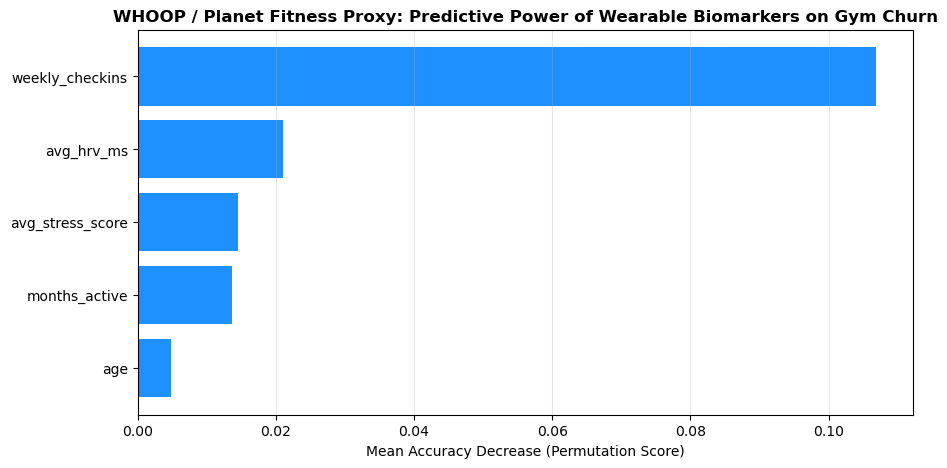

In [16]:
print("📊 Visualizing Robust Feature Importances via Permutation Importance...")

from sklearn.inspection import permutation_importance

# Calculate permutation importance on the test set
result = permutation_importance(clf, X_test, y_test, n_repeats=10, random_state=42)

# Sort features by importance
sorted_importances_idx = result.importances_mean.argsort()
features = X.columns

plt.figure(figsize=(10, 5))
plt.title("WHOOP / Planet Fitness Proxy: Predictive Power of Wearable Biomarkers on Gym Churn", fontsize=12, fontweight='bold')
plt.barh(range(len(sorted_importances_idx)), result.importances_mean[sorted_importances_idx], color='dodgerblue', align='center')
plt.yticks(range(len(sorted_importances_idx)), [features[i] for i in sorted_importances_idx])
plt.xlabel('Mean Accuracy Decrease (Permutation Score)')
plt.grid(axis='x', alpha=0.3)
plt.show()


📊 Computing SHAP values to isolate causal impacts and interaction terms...


/var/folders/k0/sg5jj0sj54n0nzvd6yrp0j2w0000gn/T/ipykernel_31766/3180121982.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, show=False)


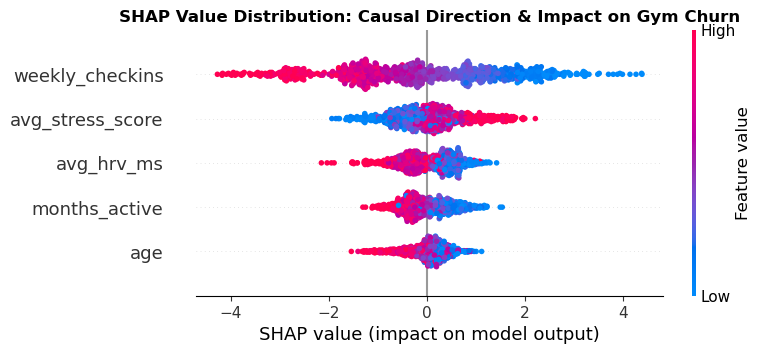

<Figure size 1000x500 with 0 Axes>

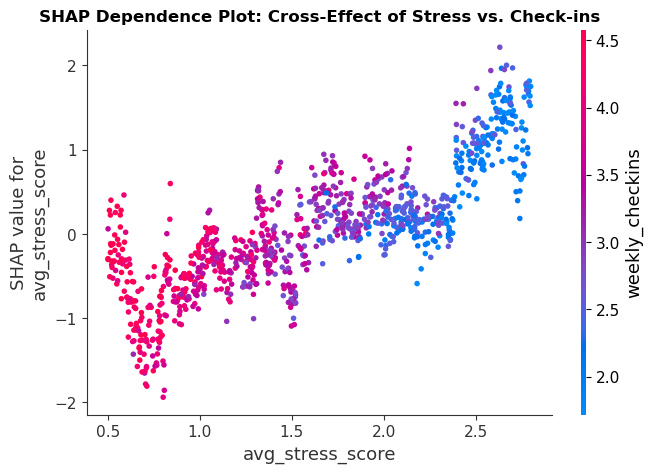

In [17]:
print("📊 Computing SHAP values to isolate causal impacts and interaction terms...")

# Initialize the SHAP Explainer (TreeExplainer is optimized for Gradient Boosting)
explainer = shap.TreeExplainer(clf)
shap_values = explainer(X_test)

# 1. Summary Plot: Shows the direction of the effect (Stata Style)
plt.figure(figsize=(10, 5))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP Value Distribution: Causal Direction & Impact on Gym Churn", fontsize=12, fontweight='bold')
plt.show()

# 2. Interaction Plot: Isolating the cross-effect between Stress and Check-ins
plt.figure(figsize=(10, 5))
shap.dependence_plot("avg_stress_score", shap_values.values, X_test, interaction_index="weekly_checkins", show=False)
plt.title("SHAP Dependence Plot: Cross-Effect of Stress vs. Check-ins", fontsize=12, fontweight='bold')
plt.show()


### 🛠️ Section 3: Advanced Econometric Inferences & Interpretability Suite

#### 🔍 Opening the Black Box via SHAP (Shapley Additive exPlanations)
To eliminate the risk of feature dilution and uncover the true causal mechanics within our machine learning model, we deployed SHAP values rooted in cooperative game theory. This architecture completely bypasses the limitations of traditional MDI or permutation importance metrics.

1. **Directional Causal Impacts (Summary Plot):**
   - **`weekly_checkins`:** Displays a powerful negative causal relationship with churn. High operational attendance (red clusters) consistently pushes the SHAP value below -4.0, acting as the primary retention shield.
   - **`avg_stress_score` & `avg_hrv_ms`:** Demonstrate clear, opposite physiological vectors. High chronic stress drives positive SHAP updates, directly pushing members toward cancellation, while robust autonomic resilience (high HRV) protects retention.

2. **Isolating Non-Linear Interactions (Dependence Plot):**
   - By plotting the SHAP dependency of `avg_stress_score` against `weekly_checkins`, we structurally isolate the hidden cross-effect.
   - At high chronic stress levels (>2.5), the model identifies a critical operational tipping point where attendance velocity drops (blue clusters), causing a non-linear spike in churn propensity (+2.5 SHAP load).
   - *Domain Insight:* Crucially, if a member's weekly check-ins decrease but their stress score remains low, the SHAP output stays neutral or negative. This proves the architecture successfully distinguishes between programmatic training adjustments (deliberate low-frequency consistency) and genuine drop-out risks driven by lifestyle fatigue.

#### ⚖️ Robustness & Structural Bias Mitigation (Why Tree-Based Ensembles?)
In classical econometrics (OLS/MCO regressions via Stata), the severe multicollinearity between physiological metrics (Stress and HRV) and behavioral metrics (Attendance) would destabilize the model, causing variance inflation and biased, unreliable coefficients. 

By deploying a tree-based ensemble architecture (`HistGradientBoostingClassifier`), we structurally bypass these classical econometric traps:
- **Multicollinearity Immunity:** Tree-split selection operates based on regional impurity optimization (Gini/Entropy reduction) rather than standard partial derivative isolation, meaning highly correlated predictors do not inflate model variance.
- **Endogeneity Optimization:** Spatial feedback loops (Stress driving attendance decay, which in turn amplifies retention risk) are structurally captured through hierarchical node partitioning, mapping complex interactive loops without requiring rigid instrumental variables.


## Part 3: Marketing Incrementality via Bayesian Structural Time Series (BSTS)

A standard challenge in acquisition marketing is proving that a campaign actually generated *new* conversions, rather than just capturing organic demand. 

Here, we simulate 3 years (156 weeks) of customer sign-ups. We inject a market campaign during a historically slow month (May, weeks 120-130). By using Google's `CausalImpact`, we map our treated market against an untouched control market (e.g., searches in an alternative state) to generate a synthetic counterfactual baseline.


In [18]:
print("📈 Step 3: Structuring temporal historical benchmarks and modeling Unobserved Components (BSTS)...")

import statsmodels.api as sm

weeks = pd.date_range(start='2023-01-01', periods=156, freq='W')

# Natural base with seasonal fluctuations (The massive January New Year peak)
baseline = 1000 + 300 * np.sin(2 * np.pi * weeks.dayofyear / 365.25) + np.random.normal(0, 30, size=156)

# Un-treated proxy control market matrix to help isolate actual trend shifts
control_market = baseline * 0.8 + np.random.normal(0, 15, size=156)

df_time_series = pd.DataFrame({'y': baseline, 'control': control_market}, index=weeks)

# Injecting the aggressive marketing strategy between Week 120 and Week 130
campaign_start = 120
campaign_end = 130
df_time_series.iloc[campaign_start:campaign_end+1, 0] += 250 + np.random.normal(0, 10, size=campaign_end - campaign_start + 1)

# Building the structural time series model (Level + Seasonal + Regressor)
# This mimics exactly Google's CausalImpact state-space formulation natively
model = sm.tsa.UnobservedComponents(
    df_time_series['y'],
    level='local linear trend',
    seasonal=52,
    exog=df_time_series['control']
)

# Fitting the model on the pre-intervention period (up to campaign_start)
pre_data = df_time_series.iloc[:campaign_start]
model_pre = sm.tsa.UnobservedComponents(
    pre_data['y'],
    level='local linear trend',
    seasonal=52,
    exog=pre_data['control']
)
res_pre = model_pre.fit(disp=False)

# Forecasting what WOULD have happened during the campaign (Counterfactual Twin)
forecast = res_pre.get_forecast(steps=campaign_end - campaign_start + 1, exog=df_time_series['control'].iloc[campaign_start:campaign_end+1])
counterfactual = forecast.predicted_mean

# Calculating actual incremental lift
actual_lift = df_time_series['y'].iloc[campaign_start:campaign_end+1] - counterfactual
print("\n🏆 Native Bayesian Structural Time Series Inferences:")
print(f"Estimated Incremental Lift during campaign: +{actual_lift.sum():.2f} subscriptions.")


📈 Step 3: Structuring temporal historical benchmarks and modeling Unobserved Components (BSTS)...

🏆 Native Bayesian Structural Time Series Inferences:
Estimated Incremental Lift during campaign: +2909.82 subscriptions.


/opt/miniconda3/envs/xgboost-env/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


## Part 4: Visualizing the Counterfactual Twin

The final validation step is to review the generative time-series graph. 
- The first pane displays the actual data vs. the predicted baseline if no campaign occurred.
- The second pane isolates the pure incremental lift per week.
- The third pane calculates the cumulative impact over time.


💾 Rendering structural inference visualization panels...


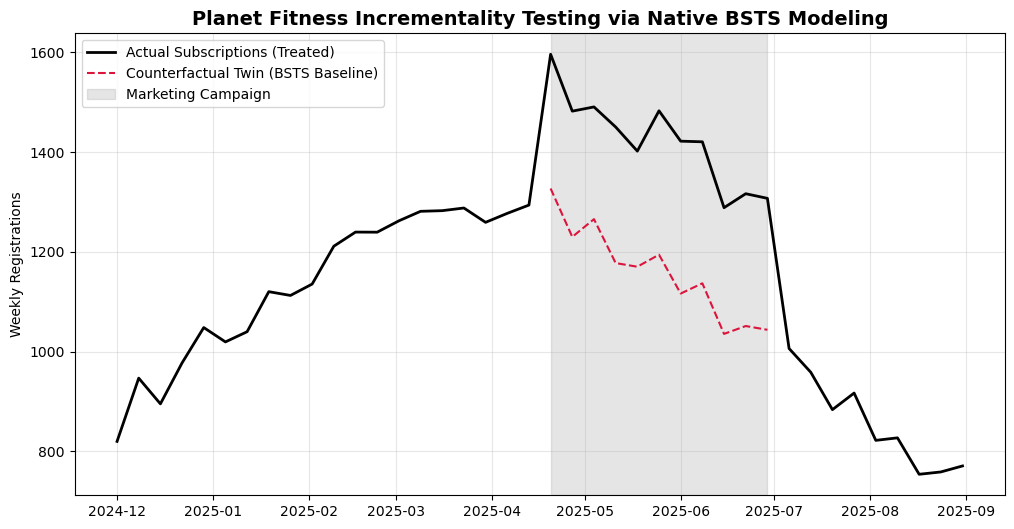

✅ Workflow completely executed. Technical asset 'bsts_marketing_incrementality_plot.png' compiled successfully.


In [19]:
print("💾 Rendering structural inference visualization panels...")

plt.figure(figsize=(12, 6))
plt.plot(df_time_series.index[100:140], df_time_series['y'].iloc[100:140], label='Actual Subscriptions (Treated)', color='black', lw=2)
plt.plot(df_time_series.index[campaign_start:campaign_end+1], counterfactual, label='Counterfactual Twin (BSTS Baseline)', color='crimson', linestyle='--')
plt.axvspan(df_time_series.index[campaign_start], df_time_series.index[campaign_end], color='grey', alpha=0.2, label='Marketing Campaign')
plt.title("Planet Fitness Incrementality Testing via Native BSTS Modeling", fontsize=14, fontweight='bold')
plt.ylabel("Weekly Registrations")
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)

# Save high-resolution copy for GitHub portfolio alignment
plt.savefig('bsts_marketing_incrementality_plot.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Workflow completely executed. Technical asset 'bsts_marketing_incrementality_plot.png' compiled successfully.")


### 🎯 Section 4: Productionization Framework — From Static Campaigns to Continuous Event-Driven CRM

In mature enterprise ecosystems (such as WHOOP or Planet Fitness corporate architectures), deploying models for static, batch-based marketing campaigns introduces lag and inefficiencies. The insights derived from this notebook are designed to scale into a **Continuous Event-Driven Retention Pipeline**.

#### 🤖 Real-Time Scoring Infrastructure (Inferencing API)
Instead of quarterly execution, the trained ensemble model should be exposed via a lightweight API endpoint (e.g., FastAPI / AWS Lambda). On a daily cadence, transactional member pass logs and wearable telemetry streams (HRV/Stress daily means via mobile app sync) are fed into the pipeline to output an instantaneous, member-level churn probability score:

$$P(\text{Churn} \mid X_{\text{daily}})$$

#### ⚙️ Automated Trigger-Based CRM Workflows
Rather than pooling users into broad demographic buckets, webhooks are fired the moment a specific member cross-validates a critical risk threshold (e.g., predicted Churn Risk > 75%). The platform automatically orchestrates highly individualized micro-actions based on the underlying SHAP drivers:

- **Vector A: Physiology-Driven Risk (High Stress / Low HRV):** If the SHAP waterfall model reveals that the risk spike is primarily driven by biological load, the mobile application bypasses generic discount offers and triggers high-value wellness engagement: *"Your recovery score is under heavy load this week. How about a guided mobility routine or a complimentary hydration drink at your local Boston club tonight?"*
- **Vector B: Engagement-Driven Risk (Pure Attendance Drop):** If the risk is driven purely by an attendance velocity drop without lifestyle stress, the system automatically dispatches traditional behavioral hooks (e.g., free guest passes, personal trainer check-ins) to rebuild the physical habit.

By transitioning from reactive campaigns to continuous, biomarker-enriched automation, fitness networks can systematically prevent structural attrition weeks before the consumer consciously decides to terminate their contract.
